# Análises para o resumo expandido do I CONAEX

Este notebook roda **depois** dos scripts de modelagem (`rodar_tudo.sh` ou `rodar_rapido.sh`). Ele não ajusta
nenhum modelo: lê as saídas em `resultados/` e gera as tabelas e as figuras do resumo expandido na pasta
`../artigo_conaex/`, que vai para o Overleaf.

| Saída | Arquivo |
|---|---|
| Tabela 1 · desempenho na escrita (KeyRecs) | `tabelas/tab_escrita.tex` |
| Tabela 2 · desempenho na leitura (CompLex) | `tabelas/tab_leitura.tex` |
| Tabela 3 · síntese dos sete métodos globais | `tabelas/tab_sintese.tex` |
| Figura 1 · fluxo da análise | `figuras/fluxo.pdf` |
| Figura 2 · importância das variáveis na escrita | `figuras/lofo_escrita.pdf` |

Rode de dentro da pasta `codigo/`. As legendas e a linha "Fonte" de cada tabela e figura ficam no `main.tex`.

## 0 · Ambiente

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch, Patch
from scipy import stats

R = Path("resultados")                       # saídas dos scripts de modelagem
ARTIGO = Path("../artigo_conaex")            # projeto do Overleaf do resumo expandido
(ARTIGO / "tabelas").mkdir(parents=True, exist_ok=True)
(ARTIGO / "figuras").mkdir(parents=True, exist_ok=True)

# Mesmo estilo das figuras do artigo (artigo/codigo_figuras/fig_lofo.py)
fonte = "Liberation Serif"
if not any(f.name == fonte for f in font_manager.fontManager.ttflist):
    fonte = "serif"
plt.rcParams.update({"font.family": fonte, "font.size": 8, "pdf.fonttype": 42,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.linewidth": 0.6, "hatch.linewidth": 0.5,
                     "xtick.major.width": 0.6, "ytick.major.width": 0.6})
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#a3a8b2"
TINTA, GRADE = "#1a1a1a", "#e3e3e3"


def f(v, casas):
    # Número com vírgula decimal; o sinal negativo vira o menos do LaTeX.
    s = f"{v:.{casas}f}".replace(".", ",")
    return f"${s}$" if s.startswith("-") else s


def salvar_tex(nome, linhas):
    caminho = ARTIGO / "tabelas" / nome
    caminho.write_text("\n".join(linhas) + "\n", encoding="utf-8")
    print("gerado:", caminho)

## 1 · Tabela 1 · Desempenho na escrita

Validação cruzada com 5 dobras repetida 10 vezes (`modelos_escrita.py`, tabela corrigida). O valor $p$ compara o
Random Forest com a regressão linear pelo teste $t$ corrigido de Nadeau e Bengio.

In [2]:
d = pd.read_csv(R / "saidas_modelos_escrita_corrigida/desempenho.csv", index_col=0)
r = json.load(open(R / "saidas_modelos_escrita_corrigida/resumo.json"))
display(d[["RMSE", "MAE", "R2"]].round(4))
print(f"p (Random Forest contra regressão linear) = {r['p_linear_vs_rf']:.3f}")

rotulo = {"Linha de base (mediana)": "Mediana", "Regressão linear": "Regressão linear$^{\\ast}$",
          "Árvore podada": "Árvore podada$^{\\ast}$", "Random Forest": "Random Forest"}
linhas = ["\\begin{tabular}{@{}lccc@{}}", "\\toprule",
          "Modelo & RMSE (s) & MAE (s) & \\Rdois \\\\", "\\midrule"]
for m, nome in rotulo.items():
    linhas.append(f"{nome} & {f(d.loc[m, 'RMSE'], 4)} & {f(d.loc[m, 'MAE'], 4)} & {f(d.loc[m, 'R2'], 2)} \\\\")
linhas += ["\\bottomrule", "\\end{tabular}", "", "\\vspace{2pt}",
           "{\\footnotesize $^{\\ast}$Interpretável por construção. Random Forest contra",
           f"regressão linear: $p = {f(r['p_linear_vs_rf'], 2)}$.\\par}}"]
salvar_tex("tab_escrita.tex", linhas)

,RMSE,MAE,R2
modelo,,,
Linha de base (mediana),0.0450,0.0360,-0.1018
Regressão linear,0.0314,0.0250,0.4224
Árvore podada,0.0351,0.0284,0.3018
Random Forest,0.0342,0.0274,0.3438


p (Random Forest contra regressão linear) = 0.325
gerado: ../artigo_conaex/tabelas/tab_escrita.tex


## 2 · Tabela 2 · Desempenho na leitura

Validação cruzada com 5 dobras repetida 10 vezes, agrupada por palavra (`modelos_leitura.py`). A precisão nos 10% é a
proporção de termos difíceis entre os 10% com maior probabilidade prevista.

In [3]:
d = pd.read_csv(R / "saidas_leitura/desempenho.csv", index_col=0)
tp = pd.read_csv(R / "saidas_leitura/testes_pareados.csv")
display(d[["auc", "prec10"]].round(3))


def p_auc(a, b):
    return tp.query("metrica == 'auc' and a == @a and b == @b")["p"].iloc[0]


interpretaveis = {"Regra das palavras raras", "Regressão logística", "Árvore podada", "EBM"}
linhas = ["\\begin{tabular}{@{}lcc@{}}", "\\toprule",
          "Modelo & AUC & Prec. 10\\% \\\\", "\\midrule"]
for m in d.index:
    nome = m + ("$^{\\ast}$" if m in interpretaveis else "")
    linhas.append(f"{nome} & {f(d.loc[m, 'auc'], 3)} & {f(d.loc[m, 'prec10'], 3)} \\\\")
linhas += ["\\bottomrule", "\\end{tabular}", "", "\\vspace{2pt}",
           "{\\footnotesize $^{\\ast}$Interpretável por construção. Prec. 10\\%: precisão nos",
           f"10\\%. AUC do Random Forest contra EBM: $p = {f(p_auc('Random Forest', 'EBM'), 2)}$;",
           f"contra regressão logística: $p = {f(p_auc('Random Forest', 'Regressão logística'), 2)}$;",
           f"contra XGBoost: $p = {f(p_auc('Random Forest', 'XGBoost'), 2)}$.\\par}}"]
salvar_tex("tab_leitura.tex", linhas)

,auc,prec10
modelo,,
Regra das palavras raras,0.849,0.382
Regressão logística,0.914,0.506
Árvore podada,0.902,0.446
EBM,0.919,0.496
Random Forest,0.919,0.491
XGBoost,0.922,0.500


gerado: ../artigo_conaex/tabelas/tab_leitura.tex


## 3 · Tabela 3 · Síntese dos sete métodos globais

Resultados de `metodos_globais.py`, `lofo_keyrecs.py`, `lofo_complex.py` e `ajuste_holm.py`. Critérios usados:

- **H de Friedman**: na escrita, as duas variáveis com mais interação; na leitura, a variável com mais interação e o
  par mais forte entre os pares com efeito relevante, isto é, com variância da dependência parcial do par de pelo
  menos 0,001. Nos demais pares o denominador do H é muito pequeno e o valor não deve ser interpretado.
- **Permutação**: variáveis com $p < 0,05$ nas mesmas 50 dobras do LOFO; na leitura, as três maiores, em AUC.
- **Remoção (LOFO)**: variáveis significativas após a correção de Holm; na leitura, em AUC.

In [4]:
g = json.load(open(R / "saidas_globais_corrigida/resumo.json"))
ge, gl = g["escrita"], g["leitura"]
nome_var = {"fix_flight_med": "tempo de voo", "fix_total_cv": "CV do tempo total"}

# H de Friedman
he = sorted(ge["H_decomp"]["H_variavel"].items(), key=lambda kv: -kv[1])[:2]
hl = sorted(gl["H_decomp"]["H_variavel"].items(), key=lambda kv: -kv[1])[0]
pares = pd.read_csv(R / "saidas_globais_corrigida/leitura_H_pares.csv")
par = pares[pares["var_pd_par"] >= 1e-3].sort_values("H", ascending=False).iloc[0]
h_esc = f"Maior H: {he[0][0]} e {he[1][0]} ({f(he[0][1], 2)} e {f(he[1][1], 2)})"
h_lei = (f"Maior H: {hl[0]} ({f(hl[1], 2)}); par relevante mais forte: "
         f"{par['par'].replace(' × ', ' e ')} ({f(par['H'], 2)})")

# Permutação nas mesmas dobras
pe = {v: x for v, x in ge["pfi_mesmas_dobras"].items() if x["p"] < 0.05}
perm_esc = ("Só o " if len(pe) == 1 else "") + ", ".join(
    f"{v} difere de zero ({f(x['media'], 1)} ms)" for v, x in pe.items())
pl = sorted(gl["pfi_mesmas_dobras"], key=lambda x: -x["media"])[:3]
perm_lei = (f"{pl[0]['variavel'].capitalize()} ({f(pl[0]['media'] / 100, 3)} na AUC), "
            f"{pl[1]['variavel']} e {pl[2]['variavel']} "
            f"({f(pl[1]['media'] / 100, 3)} e {f(pl[2]['media'] / 100, 3)})")

# Remoção (LOFO), após a correção de Holm
le = pd.read_csv(R / "saidas_holm/lofo_escrita_holm.csv").query("p_holm < 0.05")
lofo_esc = ("Só o " if len(le) == 1 else "") + "; ".join(
    f"{nome_var.get(v, v)}: +{f(ms, 1)} ms, {pct:.0f}\\% do RMSE"
    for v, ms, pct in zip(le["variavel"], le["lofo_ms"], le["pct"]))
ll = (pd.read_csv(R / "saidas_holm/lofo_leitura_holm.csv")
      .query("p_holm < 0.05").sort_values("media", ascending=False))
lofo_lei = (f"{ll.iloc[0]['variavel'].capitalize()} ({f(ll.iloc[0]['media'] / 100, 3)} na AUC), "
            f"{ll.iloc[1]['variavel']} e {ll.iloc[2]['variavel']} "
            f"({f(ll.iloc[1]['media'] / 100, 3)} e {f(ll.iloc[2]['media'] / 100, 3)})")


def substitutos(b):
    s = g[b]["substitutos"]
    return (f"Árvore: \\Rdois{{}} $= {f(s['arvore_r2'], 2).strip('$')}$; "
            f"linear: \\Rdois{{}} $= {f(s['linear_r2'], 2).strip('$')}$")


def regras(b):
    s = g[b]["regras"]
    return f"{s['n_regras']} regras e SENÃO: \\Rdois{{}} $= {f(s['fidelidade_r2_teste'], 2)}$"


me, ml = ge["mmd"], gl["mmd"]
celulas = [
    ("H de Friedman", h_esc, h_lei),
    ("Decomposição funcional",
     f"Efeitos principais: \\Rdois{{}} $= {f(ge['H_decomp']['r2_efeitos_principais'], 2)}$",
     f"Efeitos principais: \\Rdois{{}} $= {f(gl['H_decomp']['r2_efeitos_principais'], 2)}$"),
    ("Permutação", perm_esc, perm_lei),
    ("Remoção (LOFO)", lofo_esc, lofo_lei),
    ("Substitutos globais", substitutos("escrita"), substitutos("leitura")),
    ("Extração de regras", regras("escrita"), regras("leitura")),
    ("Protótipos e críticas",
     f"Erro maior nas críticas: {f(me['erro_medio_criticas'], 3)} contra "
     f"{f(me['erro_medio_prototipos'], 3)} s",
     f"Críticas bem reconhecidas: probabilidade de {f(ml['prob_media_criticas'], 2)} "
     f"contra {f(ml['prob_media_prototipos'], 2)}"),
]
display(pd.DataFrame(celulas, columns=["Método", "Escrita (KeyRecs)", "Leitura (CompLex)"]).set_index("Método"))

linhas = ["\\begin{tabular}{@{}>{\\raggedright\\arraybackslash}p{3.1cm}",
          "                >{\\raggedright\\arraybackslash}p{5.9cm}",
          "                >{\\raggedright\\arraybackslash}p{5.9cm}@{}}",
          "\\toprule", "Método & Escrita (KeyRecs) & Leitura (CompLex) \\\\", "\\midrule"]
linhas += [f"{a} & {b} & {c} \\\\" for a, b, c in celulas]
linhas += ["\\bottomrule", "\\end{tabular}"]
salvar_tex("tab_sintese.tex", linhas)

,Escrita (KeyRecs),Leitura (CompLex)
Método,,
H de Friedman,"Maior H: CV do tempo total e tempo de voo (0,1...","Maior H: frequência (0,26); par relevante mais..."
Decomposição funcional,"Efeitos principais: \Rdois{} $= 0,97$","Efeitos principais: \Rdois{} $= 0,93$"
Permutação,"Só o tempo de voo difere de zero (17,4 ms)","Frequência (0,291 na AUC), comprimento e sigla..."
Remoção (LOFO),"Só o tempo de voo: +10,4 ms, 30\% do RMSE","Frequência (0,167 na AUC), sigla e comprimento..."
Substitutos globais,"Árvore: \Rdois{} $= 0,98$; linear: \Rdois{} $=...","Árvore: \Rdois{} $= 0,91$; linear: \Rdois{} $=..."
Extração de regras,"5 regras e SENÃO: \Rdois{} $= 0,90$","5 regras e SENÃO: \Rdois{} $= 0,79$"
Protótipos e críticas,"Erro maior nas críticas: 0,043 contra 0,033 s","Críticas bem reconhecidas: probabilidade de 0,..."


gerado: ../artigo_conaex/tabelas/tab_sintese.tex


## 4 · Figura 1 · Fluxo da análise

As duas bases, o modelo preditivo e os sete métodos globais, agrupados em quatro perguntas. As medidas do desenho
estão em milímetros.

gerado: ../artigo_conaex/figuras/fluxo.pdf


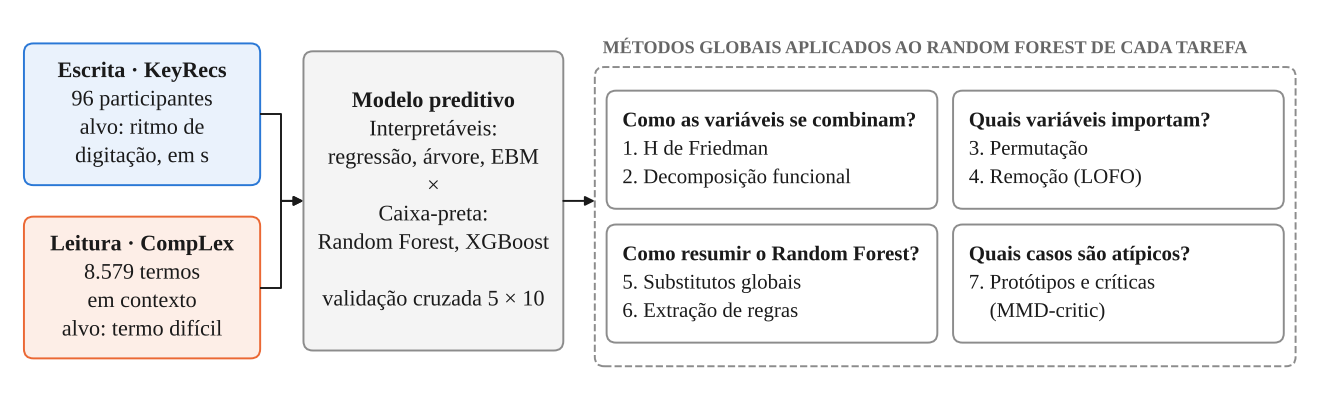

In [5]:
LINHA = 3.6                                   # altura de uma linha de texto, em mm
LARGURA, ALTURA = 163, 46
fig = plt.figure(figsize=(LARGURA / 25.4, ALTURA / 25.4))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, LARGURA)
ax.set_ylim(0, ALTURA)
ax.axis("off")


def caixa(x, y, w, h, titulo, linhas, borda="#8c8c8c", fundo="white",
          alinhar="center", tracejada=False, tamanho=8):
    # Caixa de cantos arredondados com um título em negrito e linhas de texto.
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0,rounding_size=1.2",
                                linewidth=0.7, edgecolor=borda, facecolor=fundo,
                                linestyle="--" if tracejada else "-"))
    tx = x + w / 2 if alinhar == "center" else x + 2
    topo = y + h / 2 + len(linhas) * LINHA / 2
    ax.text(tx, topo, titulo, ha=alinhar, va="center", fontweight="bold", color=TINTA, fontsize=tamanho)
    for i, linha in enumerate(linhas, start=1):
        ax.text(tx, topo - i * LINHA, linha, ha=alinhar, va="center", color=TINTA, fontsize=tamanho)


def seta(pontos):
    # Linha em cotovelo que termina em seta.
    xs, ys = zip(*pontos)
    ax.plot(xs[:-1], ys[:-1], color=TINTA, lw=0.7, solid_capstyle="butt")
    ax.annotate("", xy=pontos[-1], xytext=pontos[-2],
                arrowprops=dict(arrowstyle="-|>", lw=0.7, color=TINTA,
                                shrinkA=0, shrinkB=0, mutation_scale=7))


# bases de dados
caixa(0.5, 25, 30, 18, "Escrita · KeyRecs", ["96 participantes", "alvo: ritmo de", "digitação, em s"],
      borda=AZUL, fundo="#eaf2fc")
caixa(0.5, 3, 30, 18, "Leitura · CompLex", ["8.579 termos", "em contexto", "alvo: termo difícil"],
      borda=LARANJA, fundo="#fdeee7")
# modelo preditivo
caixa(36, 4, 33, 38, "Modelo preditivo",
      ["Interpretáveis:", "regressão, árvore, EBM", "×", "Caixa-preta:",
       "Random Forest, XGBoost", "", "validação cruzada 5 × 10"], fundo="#f4f4f4")
# sete métodos, em quatro perguntas
caixa(73, 2, 89, 38, "", [], tracejada=True)
ax.text(74, 42.5, "MÉTODOS GLOBAIS APLICADOS AO RANDOM FOREST DE CADA TAREFA",
        ha="left", va="center", fontsize=6.5, fontweight="bold", color="#666666")
caixa(74.5, 22, 42, 15, "Como as variáveis se combinam?",
      ["1. H de Friedman", "2. Decomposição funcional"], alinhar="left", tamanho=7.5)
caixa(118.5, 22, 42, 15, "Quais variáveis importam?",
      ["3. Permutação", "4. Remoção (LOFO)"], alinhar="left", tamanho=7.5)
caixa(74.5, 5, 42, 15, "Como resumir o Random Forest?",
      ["5. Substitutos globais", "6. Extração de regras"], alinhar="left", tamanho=7.5)
caixa(118.5, 5, 42, 15, "Quais casos são atípicos?",
      ["7. Protótipos e críticas", "    (MMD-critic)"], alinhar="left", tamanho=7.5)
# setas
seta([(30.5, 34), (33.2, 34), (33.2, 23), (36, 23)])
seta([(30.5, 12), (33.2, 12), (33.2, 23), (36, 23)])
seta([(69, 23), (73, 23)])

fig.savefig(ARTIGO / "figuras/fluxo.pdf")
print("gerado:", ARTIGO / "figuras/fluxo.pdf")
plt.show()

## 5 · Figura 2 · Importância das variáveis na escrita

a. LOFO do Random Forest, com intervalo de 95% corrigido para a dependência entre as 50 dobras (Nadeau e Bengio);
b. LOFO com o tempo total da senha no modelo, a variável substituta; c. permutação nas mesmas 50 dobras.
Valores de `ajuste_holm.py`, `lofo_keyrecs.py` e `lofo_complementar.py` (parte C), todos com a tabela corrigida.

gerado: ../artigo_conaex/figuras/lofo_escrita.pdf


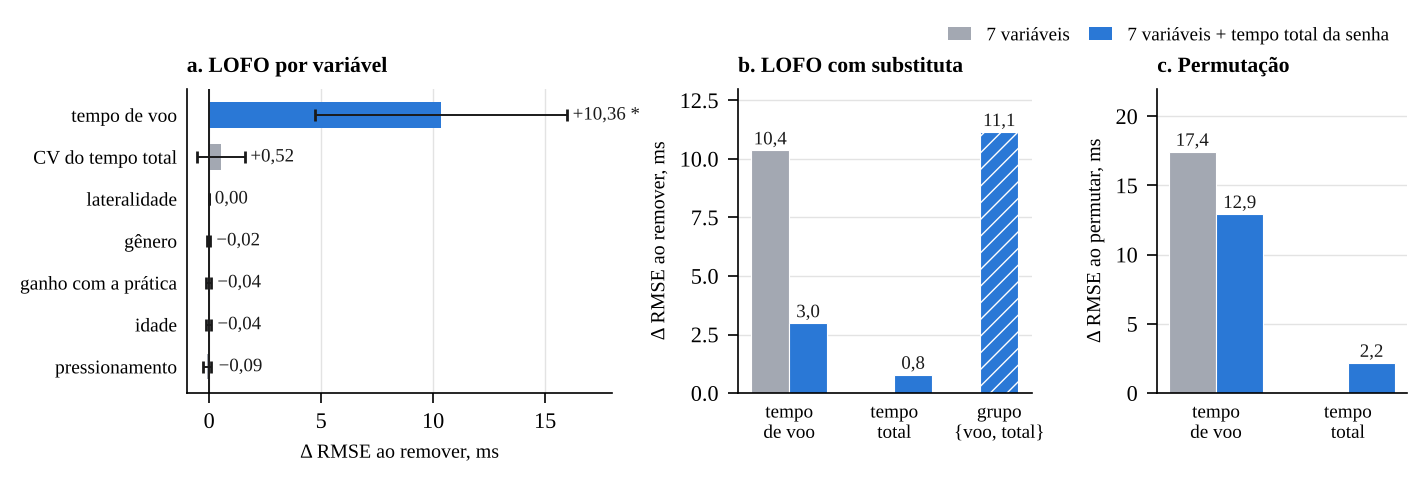

In [6]:
nomes = {"fix_flight_med": "tempo de voo", "fix_total_cv": "CV do tempo total",
         "dem_lateralidade": "lateralidade", "dem_genero": "gênero",
         "fix_ganho_pratica": "ganho com a prática", "dem_idade": "idade",
         "fix_dwell_med": "pressionamento"}
lofo = pd.read_csv(R / "saidas_holm/lofo_escrita_holm.csv").sort_values("lofo_ms", ascending=False)
red = pd.read_csv(R / "saidas_corrigida/lofo_redundancia.csv").set_index("variavel")
pfi = pd.read_csv(R / "saidas_comp_corrigida/C_pfi_mesmas_dobras.csv")
media_pfi = lambda modelo, var: pfi.query("modelo == @modelo and variavel == @var")["media"].iloc[0]

# (a) LOFO por variável, com intervalo de 95% corrigido: Var = (1/K + n_teste/n_treino) * dp^2
K, RAZAO = 50, 0.25
ic95 = stats.t.ppf(0.975, K - 1) * np.sqrt(1 / K + RAZAO) * lofo["dp_ms"].to_numpy()
signif = (lofo["p_nb"] < 0.05).to_numpy()
# (b) LOFO com a substituta e (c) permutação, nas mesmas dobras
lofo_7 = {"voo": lofo.set_index("variavel").loc["fix_flight_med", "lofo_ms"]}
lofo_8 = {"voo": red.loc["fix_flight_med", "lofo_ms"], "total": red.loc["fix_total_med", "lofo_ms"],
          "grupo": red.loc["{flight + total_med}", "lofo_ms"]}
modelo_8 = [m for m in pfi["modelo"].unique() if m != "7 variáveis"][0]
pfi_7 = {"voo": media_pfi("7 variáveis", "tempo de voo")}
pfi_8 = {"voo": media_pfi(modelo_8, "tempo de voo"), "total": media_pfi(modelo_8, "tempo total")}


def v(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",").replace("-", "−")


fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.25), gridspec_kw={"width_ratios": [1.45, 1.0, 0.85]})
ax = axes[0]
y = np.arange(len(lofo))[::-1]
val = lofo["lofo_ms"].to_numpy()
ax.barh(y, val, xerr=ic95, height=0.6, color=[AZUL if s else CINZA for s in signif],
        error_kw={"ecolor": TINTA, "capsize": 2, "lw": 0.7})
ax.axvline(0, color=TINTA, lw=0.7)
for yi, x, e, s in zip(y, val, ic95, signif):
    ax.text(max(x, 0) + e + 0.25, yi, ("+" if x > 0.005 else "") + v(x, 2) + (" *" if s else ""),
            va="center", fontsize=6.8, color=TINTA)
ax.set_yticks(y, [nomes[c] for c in lofo["variavel"]], fontsize=7)
ax.tick_params(axis="y", length=0)
ax.set_xlim(-1, 18)
ax.set_xticks([0, 5, 10, 15], ["0", "5", "10", "15"])
ax.set_xlabel("Δ RMSE ao remover, ms", fontsize=7.2)
ax.set_title("a. LOFO por variável", fontsize=7.8, loc="left", fontweight="bold")
ax.xaxis.grid(True, color=GRADE, lw=0.5)
ax.set_axisbelow(True)


def barras(ax, cats, s7, s8, titulo, ylab, ymax):
    x = np.arange(len(cats))
    w = 0.36
    for xi, (k, _) in zip(x, cats):
        if k in s7:
            ax.bar(xi - w / 2, s7[k], w, color=CINZA, edgecolor="white", lw=0.4)
            ax.text(xi - w / 2, s7[k] + ymax * 0.02, v(s7[k]), ha="center", fontsize=6.8, color=TINTA)
        if k in s8:
            pos = xi + w / 2 if k != "grupo" else xi
            ax.bar(pos, s8[k], w, color=AZUL, edgecolor="white", lw=0.4, hatch="////" if k == "grupo" else None)
            ax.text(pos, s8[k] + ymax * 0.02, v(s8[k]), ha="center", fontsize=6.8, color=TINTA)
    ax.set_xticks(x, [c[1] for c in cats], fontsize=6.9)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, ymax)
    ax.set_ylabel(ylab, fontsize=7.2)
    ax.set_title(titulo, fontsize=7.8, loc="left", fontweight="bold")
    ax.yaxis.grid(True, color=GRADE, lw=0.5)
    ax.set_axisbelow(True)


barras(axes[1], [("voo", "tempo\nde voo"), ("total", "tempo\ntotal"), ("grupo", "grupo\n{voo, total}")],
       lofo_7, lofo_8, "b. LOFO com substituta", "Δ RMSE ao remover, ms", 13)
barras(axes[2], [("voo", "tempo\nde voo"), ("total", "tempo\ntotal")],
       pfi_7, pfi_8, "c. Permutação", "Δ RMSE ao permutar, ms", 22)
fig.legend(handles=[Patch(facecolor=CINZA, label="7 variáveis"),
                    Patch(facecolor=AZUL, label="7 variáveis + tempo total da senha")],
           loc="upper right", bbox_to_anchor=(0.995, 1.02), ncol=2, frameon=False, fontsize=6.9,
           handlelength=1.2, columnspacing=1.0)
fig.tight_layout(pad=0.3, w_pad=1.2, rect=(0, 0, 1, 0.93))
fig.savefig(ARTIGO / "figuras/lofo_escrita.pdf")
print("gerado:", ARTIGO / "figuras/lofo_escrita.pdf")
plt.show()

## 6 · Arquivos gerados

In [7]:
for p in sorted((ARTIGO / "tabelas").glob("*.tex")) + sorted((ARTIGO / "figuras").glob("*.pdf")):
    print(p)

../artigo_conaex/tabelas/tab_escrita.tex
../artigo_conaex/tabelas/tab_leitura.tex
../artigo_conaex/tabelas/tab_sintese.tex
../artigo_conaex/figuras/fluxo.pdf
../artigo_conaex/figuras/lofo_escrita.pdf
